# K.R. Mangalam University
## School of Engineering & Technology

**ENSP355 – AI in Cyber Security | Capstone Lab Assignment**


# CAPSTONE: Mini AI Cybersecurity Assistant
**University:** K.R. Mangalam University  
**School:** School of Engineering & Technology  
**Course:** ENSP355 – AI in Cyber Security  
**Student Name:** Yash Raj  
**Roll Number:** 2401010008  
**Programme:** B.Tech CSE (Core)  
**Platform:** Google Colab / Python

## Aim
Build an integrated assistant that checks a sample message for phishing, malware and ransomware indicators; analyzes login activity using a Decision Tree and a small neural network; explains predictions; masks identifiers; and recommends a risk-aware action with human review.

> **Dataset note:** This notebook creates small synthetic/sanitized message and login datasets and saves them as CSV files so the notebook can run independently. If your faculty has supplied official CSV files, use those instead. Do not use real personal or institutional data.


## 1. Setup and imports

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
pd.set_option('display.max_columns', None)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 2. Create/load the two CSV datasets

The capstone requires message data and login-activity data. The following are illustrative synthetic records. The login target label is `label` (Normal/Suspicious).

In [2]:
message_data = pd.DataFrame([
    ['Your monthly statement is ready in the official portal.', 'Safe'],
    ['URGENT: verify your account password immediately using this link', 'Phishing'],
    ['Download this attachment to view your invoice', 'Malware'],
    ['Your files are locked. Pay the ransom to recover access.', 'Ransomware'],
    ['Meeting moved to 3 PM. Please confirm attendance.', 'Safe'],
    ['Your account will be suspended unless you verify now', 'Phishing'],
    ['Run this unknown executable to claim your prize', 'Malware'],
    ['Files encrypted. Send payment for the decryption key.', 'Ransomware'],
    ['Thank you for contacting customer support.', 'Safe'],
    ['Click here to reset your password immediately', 'Phishing'],
    ['Install this cracked software package', 'Malware'],
    ['Pay within 24 hours or your data will be deleted', 'Ransomware'],
], columns=['message', 'message_label'])

login_data = pd.DataFrame([
    [0, 10, 0, 40, 'Normal'],
    [1, 15, 0, 80, 'Normal'],
    [2, 9, 0, 80, 'Normal'],
    [0, 14, 0, 120, 'Normal'],
    [1, 20, 0, 60, 'Normal'],
    [3, 11, 0, 150, 'Normal'],
    [2, 2, 1, 150, 'Suspicious'],
    [7, 2, 1, 150, 'Suspicious'],
    [4, 23, 1, 400, 'Suspicious'],
    [6, 1, 0, 600, 'Suspicious'],
    [1, 3, 1, 720, 'Suspicious'],
    [5, 18, 1, 550, 'Suspicious'],
    [0, 8, 0, 700, 'Suspicious'],
    [3, 23, 1, 100, 'Suspicious'],
    [8, 4, 1, 800, 'Suspicious'],
    [0, 12, 0, 30, 'Normal'],
], columns=['failed_logins', 'login_hour', 'new_device', 'download_mb', 'label'])

message_data.to_csv('synthetic_messages.csv', index=False)
login_data.to_csv('synthetic_login_activity.csv', index=False)

print('Message dataset:')
display(message_data.head())
print('Login dataset:')
display(login_data.head())
print('Saved: synthetic_messages.csv and synthetic_login_activity.csv')

Message dataset:


,message,message_label
0,Your monthly statement is ready in the officia...,Safe
1,URGENT: verify your account password immediate...,Phishing
2,Download this attachment to view your invoice,Malware
3,Your files are locked. Pay the ransom to recov...,Ransomware
4,Meeting moved to 3 PM. Please confirm attendance.,Safe


Login dataset:


,failed_logins,login_hour,new_device,download_mb,label
0,0,10,0,40,Normal
1,1,15,0,80,Normal
2,2,9,0,80,Normal
3,0,14,0,120,Normal
4,1,20,0,60,Normal


Saved: synthetic_messages.csv and synthetic_login_activity.csv


## 3. Input cleaning and privacy masking

In [3]:
def clean_text(text):
    text = str(text).lower().strip()
    text = re.sub(r'\\s+', ' ', text)
    return text

def mask_text(text):
    text = str(text)
    # Mask email addresses, IPv4 addresses and account-like IDs.
    text = re.sub(r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\\.[A-Za-z]{2,}', '<MASKED_EMAIL>', text)
    text = re.sub(r'\\b(?:\\d{1,3}\\.){3}\\d{1,3}\\b', '<MASKED_IP>', text)
    text = re.sub(r'\\bACC[-_]?\\w+\\b', '<MASKED_ACCOUNT>', text, flags=re.IGNORECASE)
    return text

message_data['clean_message'] = message_data['message'].apply(clean_text)
display(message_data[['clean_message', 'message_label']].head())

,clean_message,message_label
0,your monthly statement is ready in the officia...,Safe
1,urgent: verify your account password immediate...,Phishing
2,download this attachment to view your invoice,Malware
3,your files are locked. pay the ransom to recov...,Ransomware
4,meeting moved to 3 pm. please confirm attendance.,Safe


## 4. Rule-based threat detector

The detector checks phishing, malware and ransomware indicators and returns a category, matched keywords and a simple keyword score. It is a transparent rule-based component, not a definitive threat verdict.

In [4]:
THREAT_KEYWORDS = {
    'Phishing': ['verify your account', 'password', 'suspended', 'click here', 'urgent'],
    'Malware': ['attachment', 'executable', 'install', 'cracked software', 'download'],
    'Ransomware': ['locked', 'ransom', 'encrypted', 'decryption key', 'pay']
}

def rule_detector(message):
    text = clean_text(message)
    matches = {}
    for category, keywords in THREAT_KEYWORDS.items():
        found = [word for word in keywords if word in text]
        if found:
            matches[category] = found

    if not matches:
        return 'Safe', [], 0

    # Select category with the greatest number of matched indicators.
    category = max(matches, key=lambda key: len(matches[key]))
    matched_words = matches[category]
    score = len(matched_words)
    return category, matched_words, score

rule_test = message_data['message'].apply(rule_detector)
message_data[['rule_category', 'matched_keywords', 'keyword_score']] = pd.DataFrame(
    rule_test.tolist(), index=message_data.index
)
display(message_data[['clean_message', 'rule_category', 'matched_keywords', 'keyword_score']])

,clean_message,rule_category,matched_keywords,keyword_score
0,your monthly statement is ready in the officia...,Safe,[],0
1,urgent: verify your account password immediate...,Phishing,"[verify your account, password, urgent]",3
2,download this attachment to view your invoice,Malware,"[attachment, download]",2
3,your files are locked. pay the ransom to recov...,Ransomware,"[locked, ransom, pay]",3
4,meeting moved to 3 pm. please confirm attendance.,Safe,[],0
5,your account will be suspended unless you veri...,Phishing,[suspended],1
6,run this unknown executable to claim your prize,Malware,[executable],1
7,files encrypted. send payment for the decrypti...,Ransomware,"[encrypted, decryption key, pay]",3
8,thank you for contacting customer support.,Safe,[],0
9,click here to reset your password immediately,Phishing,"[password, click here]",2


## 5. Decision Tree: training, testing and evaluation

Four numeric login features are used. The data is split into training and testing subsets. Accuracy and a confusion matrix are displayed.

Decision Tree accuracy: 0.750
              precision    recall  f1-score   support

      Normal       0.67      1.00      0.80         2
  Suspicious       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



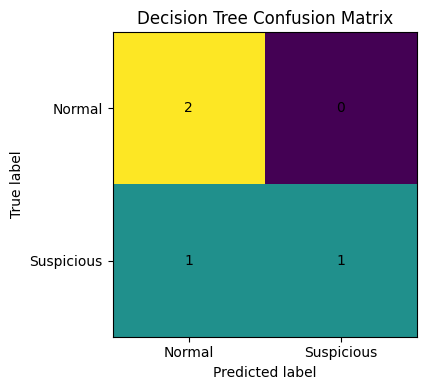

In [5]:
features = ['failed_logins', 'login_hour', 'new_device', 'download_mb']
X = login_data[features]
y = login_data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

tree_test_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_test_pred)

print(f'Decision Tree accuracy: {tree_accuracy:.3f}')
print(classification_report(y_test, tree_test_pred, zero_division=0))

cm = confusion_matrix(y_test, tree_test_pred, labels=['Normal', 'Suspicious'])
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks([0, 1], ['Normal', 'Suspicious'])
plt.yticks([0, 1], ['Normal', 'Suspicious'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout()
plt.show()

## 6. Decision Tree feature importance

,feature,importance
2,new_device,0.714286
0,failed_logins,0.285714
1,login_hour,0.000000
3,download_mb,0.000000


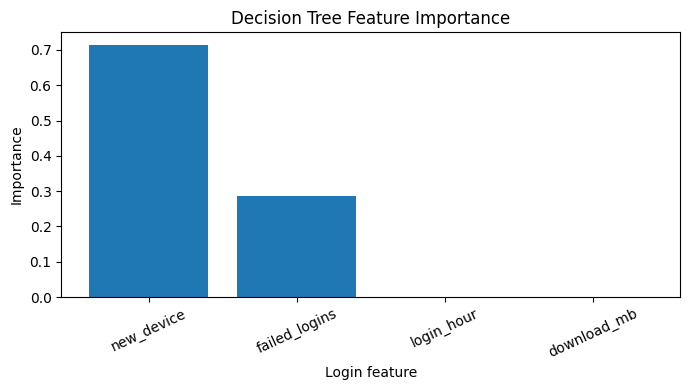

Top features:
- new_device: used by the Decision Tree to help separate Normal and Suspicious records.
- failed_logins: used by the Decision Tree to help separate Normal and Suspicious records.
- login_hour: used by the Decision Tree to help separate Normal and Suspicious records.


In [6]:
importance = pd.DataFrame({
    'feature': features,
    'importance': tree.feature_importances_
}).sort_values('importance', ascending=False)

display(importance)

plt.figure(figsize=(7, 4))
plt.bar(importance['feature'], importance['importance'])
plt.title('Decision Tree Feature Importance')
plt.ylabel('Importance')
plt.xlabel('Login feature')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print('Top features:')
for feature in importance.head(3)['feature']:
    print(f'- {feature}: used by the Decision Tree to help separate Normal and Suspicious records.')

## 7. Small neural network: training, loss and comparison

A small feed-forward neural network is trained on scaled numeric login features. A sigmoid output gives the probability of the Suspicious class.

Neural Network test accuracy: 1.000
Neural Network test loss: 0.558


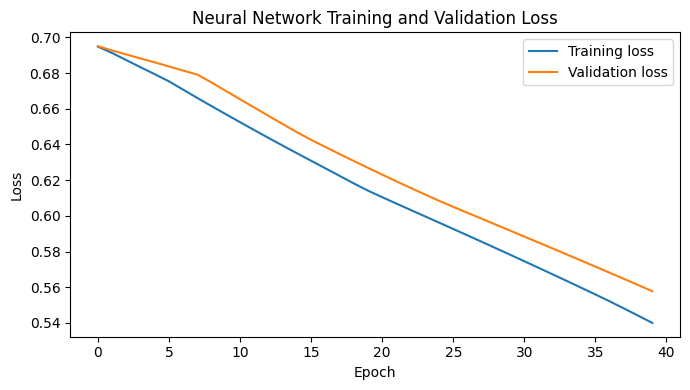

,model,test_accuracy
0,Decision Tree,0.75
1,Neural Network,1.00


In [7]:
# Encode Normal=0 and Suspicious=1.
y_binary = (y == 'Suspicious').astype(int)

X_train_nn, X_test_nn, y_train_nn, y_test_nn = train_test_split(
    X, y_binary, test_size=0.25, random_state=42, stratify=y_binary
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_nn)
X_test_scaled = scaler.transform(X_test_nn)

nn = keras.Sequential([
    layers.Input(shape=(len(features),)),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

nn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = nn.fit(
    X_train_scaled, y_train_nn,
    epochs=40, batch_size=4, verbose=0,
    validation_data=(X_test_scaled, y_test_nn)
)

nn_loss, nn_accuracy = nn.evaluate(X_test_scaled, y_test_nn, verbose=0)
print(f'Neural Network test accuracy: {nn_accuracy:.3f}')
print(f'Neural Network test loss: {nn_loss:.3f}')

plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Neural Network Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([
    {'model': 'Decision Tree', 'test_accuracy': tree_accuracy},
    {'model': 'Neural Network', 'test_accuracy': nn_accuracy}
])
display(comparison)

## 8. Integrated assistant: explanation, risk and human review

The integrated assistant combines rule, Decision Tree and neural-network results. Human review is requested for High risk, disagreement between the three modules, or low confidence. All identifiers are masked before returning the result.

In [8]:
def mask_ip(ip):
    parts = str(ip).split('.')
    return f'{parts[0]}.{parts[1]}.xxx.xxx' if len(parts) == 4 else '<MASKED_IP>'

def mask_account(account_id):
    text = str(account_id)
    return text[:4] + '***' + text[-2:] if len(text) >= 6 else '<MASKED_ACCOUNT>'

def numeric_reasons(record):
    reasons = []
    if record['failed_logins'] >= 5:
        reasons.append('many failed logins')
    if record['new_device'] == 1:
        reasons.append('new device')
    if record['login_hour'] < 6 or record['login_hour'] > 22:
        reasons.append('unusual login time')
    if record['download_mb'] >= 500:
        reasons.append('large data download')
    return reasons

def cybersecurity_assistant(message, failed_logins, login_hour, new_device,
                             download_mb, ip_address, account_id, email):
    safe_message = mask_text(message)
    rule_category, matched, keyword_score = rule_detector(safe_message)

    numeric = pd.DataFrame([{
        'failed_logins': failed_logins,
        'login_hour': login_hour,
        'new_device': new_device,
        'download_mb': download_mb
    }], columns=features)

    tree_result = tree.predict(numeric)[0]
    tree_confidence = float(tree.predict_proba(numeric).max())

    nn_probability = float(nn.predict(
        scaler.transform(numeric), verbose=0
    ).flatten()[0])
    nn_result = 'Suspicious' if nn_probability >= 0.50 else 'Normal'

    warning_votes = (
        int(rule_category != 'Safe')
        + int(tree_result == 'Suspicious')
        + int(nn_result == 'Suspicious')
    )

    conflict = len({tree_result, nn_result}) > 1
    low_confidence = tree_confidence < 0.70
    if warning_votes >= 2 or rule_category == 'Ransomware':
        risk = 'High'
        action = 'Do not interact with the message; report it to the authorized security team for verification.'
    elif warning_votes == 1 or rule_category != 'Safe':
        risk = 'Medium'
        action = 'Treat cautiously; verify through an official channel and request analyst review.'
    else:
        risk = 'Low'
        action = 'No strong indicator detected; continue normal monitoring.'

    human_review = 'Yes' if risk == 'High' or conflict or low_confidence else 'No'
    reasons = numeric_reasons(numeric.iloc[0])
    if matched:
        reasons.append('message indicators: ' + ', '.join(matched))
    if not reasons:
        reasons = ['no strong warning indicators detected']

    return {
        'masked_account': mask_account(account_id),
        'masked_ip': mask_ip(ip_address),
        'masked_email': '<MASKED_EMAIL>',
        'message_category': rule_category,
        'matched_keywords': ', '.join(matched) if matched else 'None',
        'keyword_score': keyword_score,
        'tree_prediction': tree_result,
        'tree_confidence': round(tree_confidence, 3),
        'nn_prediction': nn_result,
        'nn_suspicious_probability': round(nn_probability, 3),
        'warning_votes': warning_votes,
        'model_conflict': conflict,
        'risk': risk,
        'reason': '; '.join(reasons),
        'recommended_action': action,
        'human_review': human_review
    }

## 9. Run the five required demonstration scenarios

The scenarios follow the manual: normal message/login, urgent account verification, repeated failed logins on a new device, large download at an unusual time, and a conflicting or low-confidence result. Model outputs are data-dependent; the human-review rule explicitly handles conflict and low confidence.

In [9]:
scenarios = [
    {
        'scenario': '1. Normal message + normal login',
        'message': 'Meeting moved to 3 PM. Please confirm attendance.',
        'failed_logins': 0, 'login_hour': 10, 'new_device': 0, 'download_mb': 40
    },
    {
        'scenario': '2. Urgent account-verification message',
        'message': 'URGENT: verify your account password immediately using this link',
        'failed_logins': 1, 'login_hour': 14, 'new_device': 0, 'download_mb': 80
    },
    {
        'scenario': '3. Repeated failed logins on a new device',
        'message': 'Your normal sign-in notification',
        'failed_logins': 8, 'login_hour': 2, 'new_device': 1, 'download_mb': 150
    },
    {
        'scenario': '4. Large download at unusual time',
        'message': 'Routine system notification',
        'failed_logins': 1, 'login_hour': 23, 'new_device': 0, 'download_mb': 750
    },
    {
        'scenario': '5. Conflict / low-confidence test',
        'message': 'Please review this routine account notice.',
        'failed_logins': 3, 'login_hour': 8, 'new_device': 1, 'download_mb': 250
    }
]

scenario_outputs = []
for s in scenarios:
    result = cybersecurity_assistant(
        message=s['message'],
        failed_logins=s['failed_logins'],
        login_hour=s['login_hour'],
        new_device=s['new_device'],
        download_mb=s['download_mb'],
        ip_address='192.168.10.24',
        account_id='ACC-2001',
        email='student@example.com'
    )
    result['scenario'] = s['scenario']
    scenario_outputs.append(result)

final_results = pd.DataFrame(scenario_outputs)
display(final_results)

,masked_account,masked_ip,masked_email,message_category,matched_keywords,keyword_score,tree_prediction,tree_confidence,nn_prediction,nn_suspicious_probability,warning_votes,model_conflict,risk,reason,recommended_action,human_review,scenario
0,ACC-***01,192.168.xxx.xxx,<MASKED_EMAIL>,Safe,None,0,Normal,1.0,Normal,0.360,0,False,Low,no strong warning indicators detected,No strong indicator detected; continue normal ...,No,1. Normal message + normal login
1,ACC-***01,192.168.xxx.xxx,<MASKED_EMAIL>,Phishing,"verify your account, password, urgent",3,Normal,1.0,Normal,0.360,1,False,Medium,"message indicators: verify your account, passw...",Treat cautiously; verify through an official c...,No,2. Urgent account-verification message
2,ACC-***01,192.168.xxx.xxx,<MASKED_EMAIL>,Safe,None,0,Suspicious,1.0,Suspicious,0.525,2,False,High,many failed logins; new device; unusual login ...,Do not interact with the message; report it to...,Yes,3. Repeated failed logins on a new device
3,ACC-***01,192.168.xxx.xxx,<MASKED_EMAIL>,Safe,None,0,Normal,1.0,Suspicious,0.546,1,True,Medium,unusual login time; large data download,Treat cautiously; verify through an official c...,Yes,4. Large download at unusual time
4,ACC-***01,192.168.xxx.xxx,<MASKED_EMAIL>,Safe,None,0,Suspicious,1.0,Suspicious,0.551,2,False,High,new device,Do not interact with the message; report it to...,Yes,5. Conflict / low-confidence test


## 10. Risk/category chart

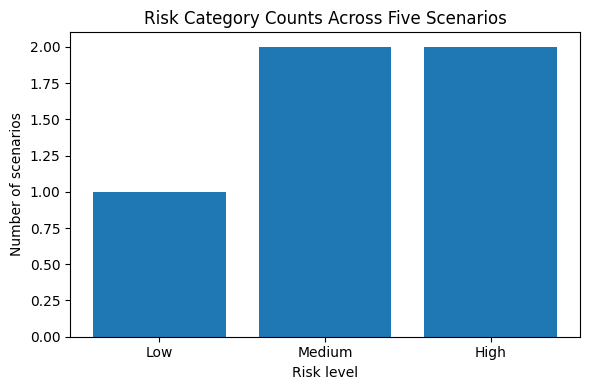

Risk counts:


,count
risk,
Low,1
Medium,2
High,2


In [10]:
risk_counts = final_results['risk'].value_counts().reindex(['Low', 'Medium', 'High'], fill_value=0)

plt.figure(figsize=(6, 4))
plt.bar(risk_counts.index, risk_counts.values)
plt.title('Risk Category Counts Across Five Scenarios')
plt.xlabel('Risk level')
plt.ylabel('Number of scenarios')
plt.tight_layout()
plt.show()

print('Risk counts:')
display(risk_counts.rename('count').to_frame())

## 11. Save final combined result table and CSV outputs

In [11]:
# Save a privacy-aware final result table.
final_results.to_csv('final_combined_results.csv', index=False)
message_data[['clean_message', 'message_label', 'rule_category',
              'matched_keywords', 'keyword_score']].to_csv('message_analysis_results.csv', index=False)
login_data.to_csv('login_activity_synthetic.csv', index=False)

print('Saved files:')
print('- synthetic_messages.csv')
print('- synthetic_login_activity.csv')
print('- message_analysis_results.csv')
print('- login_activity_synthetic.csv')
print('- final_combined_results.csv')

display(final_results[['scenario', 'message_category', 'tree_prediction',
                       'nn_prediction', 'risk', 'human_review']])

Saved files:
- synthetic_messages.csv
- synthetic_login_activity.csv
- message_analysis_results.csv
- login_activity_synthetic.csv
- final_combined_results.csv


,scenario,message_category,tree_prediction,nn_prediction,risk,human_review
0,1. Normal message + normal login,Safe,Normal,Normal,Low,No
1,2. Urgent account-verification message,Phishing,Normal,Normal,Medium,No
2,3. Repeated failed logins on a new device,Safe,Suspicious,Suspicious,High,Yes
3,4. Large download at unusual time,Safe,Normal,Suspicious,Medium,Yes
4,5. Conflict / low-confidence test,Safe,Suspicious,Suspicious,High,Yes


## 12. Responsible-use and human-review checklist

In [12]:
responsible_use_checklist = [
    'Use only synthetic or sanitized datasets.',
    'Do not open suspicious links or execute malware.',
    'Do not scan networks or test live accounts.',
    'Do not upload institutional confidential data to Colab.',
    'Mask identifiers in screenshots, charts and reports.',
    'Treat model outputs as decision support, not proof.',
    'Require authorized human verification before serious action.',
    'Request human review for High risk, model conflict or low confidence.'
]
for item in responsible_use_checklist:
    print('☐', item)

☐ Use only synthetic or sanitized datasets.
☐ Do not open suspicious links or execute malware.
☐ Do not scan networks or test live accounts.
☐ Do not upload institutional confidential data to Colab.
☐ Mask identifiers in screenshots, charts and reports.
☐ Treat model outputs as decision support, not proof.
☐ Require authorized human verification before serious action.
☐ Request human review for High risk, model conflict or low confidence.


## 13. Observations and limitations

### Observations
- The rule-based module returns a threat category and matched keywords, making its reasoning visible.
- The Decision Tree returns a Normal/Suspicious prediction and confidence.
- The neural network returns a probability for the Suspicious class.
- The combined table compares all three modules and records risk, recommended action and human-review status.
- The feature-importance and risk charts summarize model behaviour and scenario risk.

### Limitations
- The datasets are small and synthetic; accuracy does not demonstrate real-world performance.
- Keyword rules can miss new wording and may flag harmless messages containing threat-related words.
- A Decision Tree and a small neural network can make incorrect predictions.
- Neural-network probabilities and Decision Tree confidence are not guarantees of correctness.
- The prototype is decision support only. It must not automatically punish users, block accounts or take other high-impact actions.

## 14. Conclusion

The capstone integrates input cleaning and privacy masking, a rule-based threat detector, a supervised Decision Tree, a small neural network, model comparison, explainability, risk assignment and human-review controls. Five demonstration scenarios were evaluated and a combined privacy-aware result table was saved. The prototype demonstrates an AI-assisted cybersecurity workflow using synthetic data; real security decisions require validation and authorized human review.

## 15. Final submission checklist

In [13]:
submission_checklist = [
    'All notebook cells executed without unresolved errors',
    'Two CSV datasets saved',
    'Final combined result table saved',
    'Risk/category chart and feature-importance chart visible',
    'All five demonstration scenarios tested',
    'Privacy and responsible-use checklist included',
    'Model conflicts and low confidence trigger human review',
    'Two-to-three page report completed',
    'Five-slide presentation completed',
    'Colab sharing permission enabled and ZOSIMA submission completed'
]
for item in submission_checklist:
    print('☐', item)

☐ All notebook cells executed without unresolved errors
☐ Two CSV datasets saved
☐ Final combined result table saved
☐ Risk/category chart and feature-importance chart visible
☐ All five demonstration scenarios tested
☐ Privacy and responsible-use checklist included
☐ Model conflicts and low confidence trigger human review
☐ Two-to-three page report completed
☐ Five-slide presentation completed
☐ Colab sharing permission enabled and ZOSIMA submission completed


**Before submission:** Run all cells in Colab and confirm outputs. Download the generated CSV files from the Colab Files panel. The manual also requires a 2–3 page report, a five-slide presentation and a one-page responsible-use checklist; those are separate deliverables beyond this notebook. Share the notebook using Colab's Share option and submit it through the institution's required platform.